# Loading the data

In [1]:
import numpy as np
data = np.genfromtxt("churn-data.csv", delimiter=",", dtype=float, names=True)
feature_names = list(data.dtype.names[:-1])
target_name = data.dtype.names[-1]
X = np.array([data[feature] for feature in feature_names]).T
y = data[target_name].astype(int)
print(f"Feature columns names: {feature_names}")
print(f"Target column name: {target_name}")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

Feature columns names: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']
Target column name: Churn
X shape: (7032, 19)
y shape: (7032,)


# 2.1 Model selection

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

from decision_tree import DecisionTree

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## Train / test split

The test set is split off once and remains untouched until the final evaluation.
Hyperparameters are selected with cross-validation on the training portion.

All splits are stratified so that the ~26.5% churn rate is preserved in both
subsets.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

for name, subset in [("train", y_train), ("test", y_test)]:
    print(f"{name:5s}: n = {len(subset):5d}, churn rate = {subset.mean():.3f}")


train: n =  5625, churn rate = 0.266
test : n =  1407, churn rate = 0.266


### Checking for NaN and carinality per column 

In [4]:
print("NaNs:", np.isnan(X).sum())


for name, col in zip(feature_names, X.T):
    u = np.unique(col)
    print(f"{name:25s} {len(u):5d} unique" + (f"  -> {u}" if len(u) <= 5 else ""))

NaNs: 0
gender                        2 unique  -> [0. 1.]
SeniorCitizen                 2 unique  -> [0. 1.]
Partner                       2 unique  -> [0. 1.]
Dependents                    2 unique  -> [0. 1.]
tenure                       72 unique
PhoneService                  2 unique  -> [0. 1.]
MultipleLines                 3 unique  -> [0. 1. 2.]
InternetService               3 unique  -> [0. 1. 2.]
OnlineSecurity                3 unique  -> [0. 1. 2.]
OnlineBackup                  3 unique  -> [0. 1. 2.]
DeviceProtection              3 unique  -> [0. 1. 2.]
TechSupport                   3 unique  -> [0. 1. 2.]
StreamingTV                   3 unique  -> [0. 1. 2.]
StreamingMovies               3 unique  -> [0. 1. 2.]
Contract                      3 unique  -> [0. 1. 2.]
PaperlessBilling              2 unique  -> [0. 1.]
PaymentMethod                 4 unique  -> [0. 1. 2. 3.]
MonthlyCharges             1584 unique
TotalCharges               6530 unique



## Hyperparameter grid

 The DecisionTree exposes exactly two hyperparameters, so both get tuned:
 - `criterion`: entropy vs gini
 - `max_depth`: the main capacity / overfitting control

 The depth grid is dense at the low end (where the accuracy changes fastest) and
 includes `None` so that a fully grown tree is part of the comparison rather than
 an assumption.

In [5]:

criteria = ["entropy", "gini"]
max_depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, None]

param_grid = [
    {"criterion": c, "max_depth": d}
    for c in criteria
    for d in max_depths
]
print(f"{len(param_grid)} configurations to evaluate")


28 configurations to evaluate


 ## Cross-validated grid search

 5-fold stratified cross-validation on the training set. Each configuration is
 trained and scored 5 times on disjoint validation folds, and the scores are
 averaged. This is more reliable than a single hold-out because it uses every
 training point for validation exactly once, and the standard deviation across
 folds gives a sense of how stable each configuration is.

 Accuracy is recorded but is NOT the selection metric: with a 73/27 class split,
 always predicting "no churn" already scores ~73% accuracy while being useless.
 F1 on the churn class is the selection metric, since it balances precision and
 recall on the minority class that the task actually cares about.
 Balanced accuracy is logged as a sanity check.



In [6]:

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

records = []
for params in param_grid:
    fold_acc, fold_f1, fold_bal = [], [], []

    for train_idx, valid_idx in cv.split(X_train, y_train):
        model = DecisionTree(**params)
        model.fit(X_train[train_idx], y_train[train_idx])
        preds = model.predict(X_train[valid_idx])

        fold_acc.append(accuracy_score(y_train[valid_idx], preds))
        fold_f1.append(f1_score(y_train[valid_idx], preds, zero_division=0))
        fold_bal.append(balanced_accuracy_score(y_train[valid_idx], preds))

    records.append({
        "criterion": params["criterion"],
        "max_depth": params["max_depth"],
        "cv_accuracy": np.mean(fold_acc),
        "cv_f1": np.mean(fold_f1),
        "cv_f1_std": np.std(fold_f1),
        "cv_balanced_acc": np.mean(fold_bal),
    })

results = pd.DataFrame(records)
results.sort_values("cv_f1", ascending=False).head(10)

,criterion,max_depth,cv_accuracy,cv_f1,cv_f1_std,cv_balanced_acc
1,entropy,2.0,0.745422,0.601577,0.012104,0.738294
15,gini,2.0,0.745422,0.601577,0.012104,0.738294
19,gini,6.0,0.790222,0.573507,0.011917,0.707562
18,gini,5.0,0.792178,0.563121,0.025404,0.701425
5,entropy,6.0,0.787733,0.558659,0.033841,0.698825
20,gini,7.0,0.784000,0.551304,0.044321,0.695216
7,entropy,8.0,0.782756,0.550283,0.042122,0.693941
6,entropy,7.0,0.784889,0.549466,0.037522,0.693047
4,entropy,5.0,0.789867,0.546575,0.031603,0.691742
22,gini,9.0,0.768356,0.544175,0.038588,0.690110


## Validation curves

Plotting the scores against depth shows *why* a configuration wins, not just
that it did: the characteristic rise-then-fall of the validation score is the
overfitting point, where extra depth starts fitting training noise.


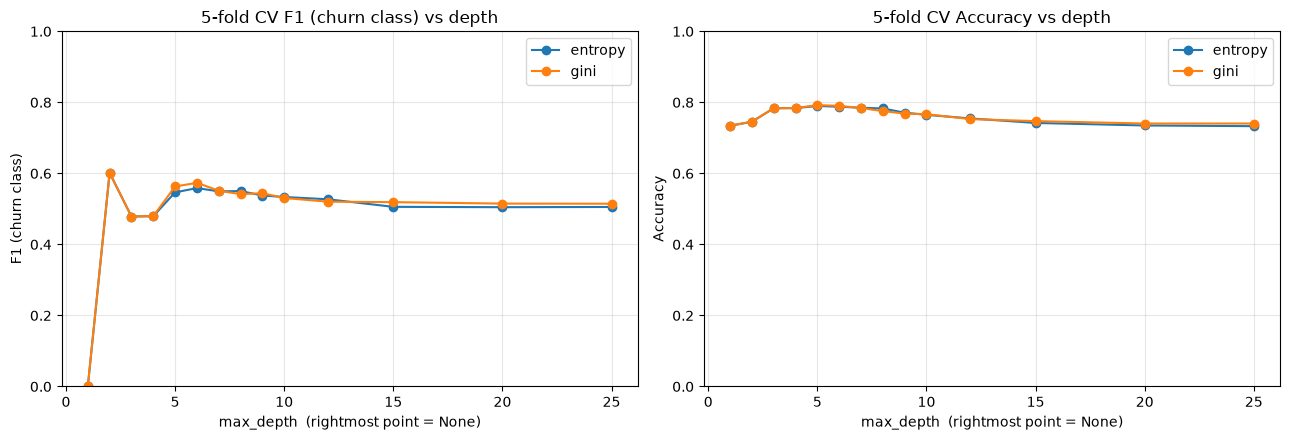

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
depth_labels = [d if d is not None else max(x for x in max_depths if x is not None) + 5
                for d in max_depths]

for ax, metric, title in zip(axes, ["cv_f1", "cv_accuracy"], ["F1 (churn class)", "Accuracy"]):
    for c in criteria:
        subset = results[results["criterion"] == c].set_index("max_depth", drop=False)
        scores = [subset[subset["max_depth"].isna() if d is None else subset["max_depth"] == d][metric].iloc[0]
                  for d in max_depths]
        ax.plot(depth_labels, scores, marker="o", label=c)
    ax.set_xlabel("max_depth  (rightmost point = None)")
    ax.set_ylabel(title)
    ax.set_ylim(0, 1)
    ax.set_title(f"5-fold CV {title} vs depth")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()



## Select the best configuration

 Ties are broken toward the shallower tree: when two configurations are
 statistically indistinguishable, the simpler model is preferred because it
 generalises more reliably and is easier to interpret.

In [8]:
best_f1 = results["cv_f1"].max()
tolerance = results.loc[results["cv_f1"].idxmax(), "cv_f1_std"]

within_tolerance = results[results["cv_f1"] >= best_f1 - tolerance].copy()
within_tolerance["depth_for_sort"] = within_tolerance["max_depth"].fillna(np.inf)
best_row = within_tolerance.sort_values("depth_for_sort").iloc[0]

best_params = {
    "criterion": best_row["criterion"],
    "max_depth": None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"]),
}

print(f"Best CV F1 in grid:      {best_f1:.4f}")
print(f"Selected (simplest within 1 std): {best_params}")
print(f"  CV F1       = {best_row['cv_f1']:.4f} (+/- {best_row['cv_f1_std']:.4f})")
print(f"  CV accuracy = {best_row['cv_accuracy']:.4f}")


Best CV F1 in grid:      0.6016
Selected (simplest within 1 std): {'criterion': 'entropy', 'max_depth': 2}
  CV F1       = 0.6016 (+/- 0.0121)
  CV accuracy = 0.7454


## Final model

Once the hyperparameters are fixed, the model is refitted on the full training
split. The test set is scored here once and is not used for model selection.


In [9]:
final_model = DecisionTree(**best_params)
final_model.fit(X_train, y_train)
test_preds = final_model.predict(X_test)

print("Final model on the test set")
print(f"  accuracy          = {accuracy_score(y_test, test_preds):.4f}")
print(f"  F1 (churn)        = {f1_score(y_test, test_preds, zero_division=0):.4f}")
print(f"  balanced accuracy = {balanced_accuracy_score(y_test, test_preds):.4f}")


Final model on the test set
  accuracy          = 0.7285
  F1 (churn)        = 0.5784
  balanced accuracy = 0.7196


## Sklearn model

In [10]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

sklearn_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid={"criterion": criteria, "max_depth": max_depths},
    scoring="f1",
    cv=cv,
    refit=True,
    return_train_score=False,
)
sklearn_search.fit(X_train, y_train)

sklearn_model = sklearn_search.best_estimator_
sklearn_preds = sklearn_model.predict(X_test)

print("Best sklearn configuration:", sklearn_search.best_params_)
print("Sklearn model on the test set")
print(f"  accuracy          = {accuracy_score(y_test, sklearn_preds):.4f}")
print(f"  F1 (churn)        = {f1_score(y_test, sklearn_preds, zero_division=0):.4f}")
print(f"  balanced accuracy = {balanced_accuracy_score(y_test, sklearn_preds):.4f}")


Best sklearn configuration: {'criterion': 'entropy', 'max_depth': 2}
Sklearn model on the test set
  accuracy          = 0.7285
  F1 (churn)        = 0.5784
  balanced accuracy = 0.7196


## Reproducibility

In [11]:
import sys, sklearn
print(f"random seed : {RANDOM_STATE}")
print(f"python      : {sys.version.split()[0]}")
print(f"numpy       : {np.__version__}")
print(f"pandas      : {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")

random seed : 42
python      : 3.14.8
numpy       : 2.5.4
pandas      : 3.1.1
scikit-learn: 1.9.1


# 3 Feature importance

Permutation importance is computed on the **test set**, as the assignment
specifies, using the final model and accuracy as the metric.

Note the ordering constraint: the final model must already be fitted and the
test score already reported before this runs. Permutation importance is a
model *inspection* technique, not a model selection one — nothing below may
feed back into any choice about the model, or the test set stops being a clean
generalisation estimate.
 

In [12]:
from decision_tree import permutation_importance
 
N_REPEATS = 30
 
result = permutation_importance(
    final_model, X_test, y_test,
    metric=accuracy_score,
    n_repeats=N_REPEATS,
    seed=RANDOM_STATE,
)
 
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance_mean": result["importances_mean"],
    "importance_std": result["importances_std"],
}).sort_values("importance_mean", ascending=False).reset_index(drop=True)
 
print(f"Reference accuracy (unpermuted): {result['reference_score']:.4f}")
print(f"n_repeats = {N_REPEATS}, seed = {RANDOM_STATE}\n")
importance_df

Reference accuracy (unpermuted): 0.7285
n_repeats = 30, seed = 42



,feature,importance_mean,importance_std
0,OnlineSecurity,0.042739,0.008153
1,Contract,0.042597,0.007354
2,gender,0.000000,0.000000
3,Partner,0.000000,0.000000
4,SeniorCitizen,0.000000,0.000000
5,PhoneService,0.000000,0.000000
6,Dependents,0.000000,0.000000
7,MultipleLines,0.000000,0.000000
8,InternetService,0.000000,0.000000
9,OnlineBackup,0.000000,0.000000


## Bar plot

Only features the model actually uses can have non-zero importance, so the
plot is restricted to those. Error bars show one standard deviation across the
30 repeats — a feature whose bar is smaller than its own error bar has not
been shown to matter.

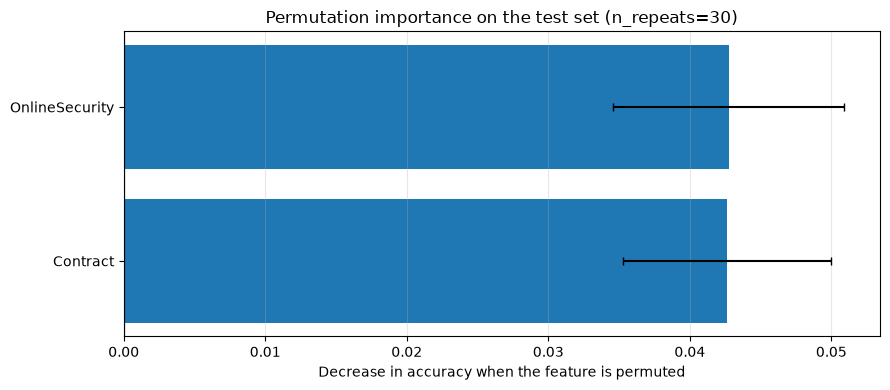

2 of 19 features have non-zero importance; the remaining 17 are never used by the tree.


In [13]:
nonzero = importance_df[importance_df["importance_mean"] != 0].copy()
plot_df = nonzero.iloc[::-1]  # largest at the top of a horizontal bar chart
 
fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(plot_df))))
ax.barh(plot_df["feature"], plot_df["importance_mean"],
        xerr=plot_df["importance_std"], capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Decrease in accuracy when the feature is permuted")
ax.set_title(f"Permutation importance on the test set (n_repeats={N_REPEATS})")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
 
print(f"{len(nonzero)} of {len(feature_names)} features have non-zero importance; "
      f"the remaining {len(feature_names) - len(nonzero)} are never used by the tree.")

## Full distribution of the top features

A box plot over the 30 repeats shows the spread behind each mean, which the
bar plot compresses into a single number.

C:\Users\tobmu\AppData\Local\Temp\ipykernel_26500\2315678015.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(result["importances"][top_idx].T, vert=False,


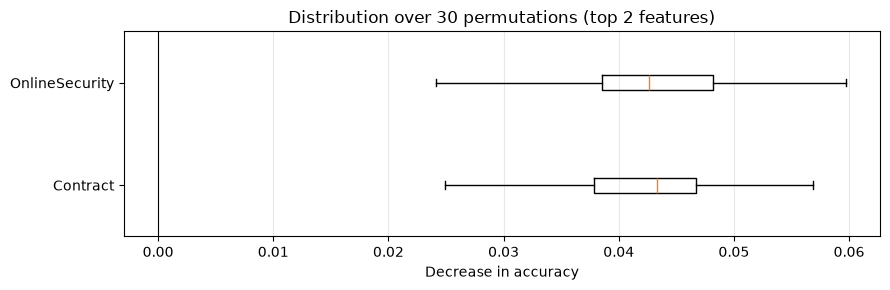

In [14]:
top_k = min(10, len(nonzero))
top_idx = [feature_names.index(f) for f in importance_df["feature"].head(top_k)]
 
fig, ax = plt.subplots(figsize=(9, 0.5 * top_k + 2))
ax.boxplot(result["importances"][top_idx].T, vert=False,
           tick_labels=importance_df["feature"].head(top_k))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Decrease in accuracy")
ax.set_title(f"Distribution over {N_REPEATS} permutations (top {top_k} features)")
ax.grid(axis="x", alpha=0.3)
ax.invert_yaxis()
plt.tight_layout()
plt.show()
 